# Nepal case study: the August 2026 Bhote Koshi - Trishuli flood

A glacial lake outburst flood on the night of 25 August 2026 sent a debris flood down the
Bhote Koshi and Trishuli valleys. The flood model never saw this event, or terrain like it.

Inputs: Sentinel-1 radar on 16 August (before) and 28 August (after), same orbit, and the Copernicus
DEM. Reference: the UNOSAT flood extent of 26-27 August, mapped from optical imagery.

## Settings

In [ ]:
DRIVE_ROOT = "/content/drive/MyDrive/flood_triage"
RUN_DIR = f"{DRIVE_ROOT}/runs/terramind_tiny_s1dem_t2"
CKPT = f"{RUN_DIR}/checkpoints/best_val_loss.ckpt"
SPOTTER_DIR = f"{RUN_DIR}/spotter"
OUT_DIR = f"{RUN_DIR}/nepal"
NEPAL = f"{DRIVE_ROOT}/nepal"

FILES = {
    "s1_pre": f"{NEPAL}/s1/s1rtc_20260816_orbit85_ascending.tif",
    "s1_post": f"{NEPAL}/s1/s1rtc_20260828_orbit85_ascending.tif",
    "dem": f"{NEPAL}/dem/copdem_glo30.tif",
    "extent": f"{NEPAL}/unosat/extent/FloodExtent_20260826_Nepal.shp",
    "area": f"{NEPAL}/unosat/analysis/UNOSAT_Analysis_extent_20260826_20260827.shp",
}
MODALITIES = ["S1RTC", "DEM"]
RANKINGS = ["random", "flood_fraction", "entropy", "spotter", "oracle"]

## Google Drive

In [10]:
import os
from google.colab import drive
drive.mount("/content/drive")

for name, path in FILES.items():
    print(f"{name:8s} {'ok' if os.path.exists(path) else 'MISSING'}  {path}")
assert all(os.path.exists(p) for p in FILES.values()) and os.path.exists(CKPT)
os.makedirs(OUT_DIR, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
s1_pre   ok  /content/drive/MyDrive/flood_triage/nepal/s1/s1rtc_20260816_orbit85_ascending.tif
s1_post  ok  /content/drive/MyDrive/flood_triage/nepal/s1/s1rtc_20260828_orbit85_ascending.tif
dem      ok  /content/drive/MyDrive/flood_triage/nepal/dem/copdem_glo30.tif
extent   ok  /content/drive/MyDrive/flood_triage/nepal/unosat/extent/FloodExtent_20260826_Nepal.shp
area     ok  /content/drive/MyDrive/flood_triage/nepal/unosat/analysis/UNOSAT_Analysis_extent_20260826_20260827.shp


## Install

In [ ]:
%%capture install_log
!pip install terratorch==1.2.1 zarr==2.18.0 numcodecs==0.15.1 xarray==2025.10.1 torchgeo==0.9.0 webdataset==1.0.2 rasterio
!test -d /content/ImpactMesh || git clone -q https://github.com/IBM/ImpactMesh.git /content/ImpactMesh
!git -C /content/ImpactMesh checkout -q 451038f21264256590eee0c73bec958897895213
!pip install -e /content/ImpactMesh --no-deps

In [12]:
import subprocess, sys

check = "import torch, importlib.metadata as m; import webdataset, impactmesh, rasterio; print(torch.__version__, torch.cuda.is_available(), m.version('terratorch'))"
r = subprocess.run([sys.executable, "-c", check], capture_output=True, text=True)
print(r.stdout, r.stderr[-2000:])

2.11.0+cu128 True 1.2.1
 


In [ ]:
# stop here if the install changed packages this session has already loaded
import importlib.metadata, importlib.util, numpy
if numpy.__version__ != importlib.metadata.version("numpy") or importlib.util.find_spec("impactmesh") is None:
    raise RuntimeError("Packages were just installed or updated: click Restart in the notebook toolbar, then Run All.")
print("environment ready")

## Project code

In [ ]:
!mkdir -p /content/code

In [14]:
%%writefile /content/code/triage_data.py
"""Reads the training shards.

Each sample holds s2l2a, s1rtc, dem and mask arrays (.npy, Blosc-compressed) and a meta.json.
Shapes: S2L2A (2, 12, 256, 256), S1RTC (2, 2, 256, 256), DEM (1, 256, 256), mask (256, 256);
time 0 is pre-event and time 1 is the event.
"""
import io
import json
import os
from functools import partial

import numpy as np
from numcodecs import Blosc

CODEC = Blosc(cname="zstd", clevel=5, shuffle=Blosc.SHUFFLE)
FILES = {"S2L2A": "s2l2a.npy.blosc", "S1RTC": "s1rtc.npy.blosc", "DEM": "dem.npy.blosc"}


def load_array(data):
    return np.load(io.BytesIO(CODEC.decode(data)))


def decode_sample(sample, modalities=("S2L2A", "S1RTC", "DEM")):
    """Raw shard sample -> the dict the ImpactMesh transforms expect. Only the given modalities
    are decompressed, which saves CPU time when training without S2."""
    out = {"__key__": sample["__key__"], "meta": json.loads(sample["meta.json"])}
    for mod in modalities:
        out[mod] = load_array(sample[FILES[mod]])
    out["mask"] = load_array(sample["mask.npy.blosc"]).astype(np.int64)
    return out


IMPORT_ERROR = None   # set if the datamodule could not be defined

try:  # the datamodule needs torch, terratorch and impactmesh
    if os.environ.get("TRIAGE_NO_TORCH") == "1":
        raise ImportError("TRIAGE_NO_TORCH is set")
    import webdataset as wds
    from torch.utils.data._utils.collate import default_collate
    from impactmesh.wds_impactmesh_datamodule import WdsImpactMeshDataModule
    from impactmesh.wds_impactmesh_dataset import make_transform

    class TriageWdsDataModule(WdsImpactMeshDataModule):
        """The ImpactMesh WebDataset datamodule, reading our shards. URLs can be one brace
        pattern or a list of them."""

        def _pipeline(self, urls, transform, shuffle):
            if isinstance(urls, (list, tuple)):
                urls = [u for pat in urls for u in wds.shardlists.expand_urls(pat)]
            steps = [
                wds.ResampledShards(urls) if shuffle else wds.SimpleShardList(urls),
                wds.split_by_node,
                wds.split_by_worker,
                wds.tarfile_to_samples(),
                wds.map(partial(decode_sample, modalities=tuple(self.modalities))),
            ]
            if shuffle:
                steps.append(wds.shuffle(self.shuffle_buffer))
            steps.append(wds.map(make_transform(
                self.modalities, self.timesteps, self.no_data_value,
                self.no_data_replace, transform, self.concat_bands)))
            steps.append(wds.batched(self.batch_size, collation_fn=default_collate, partial=not shuffle))
            return wds.DataPipeline(*steps)
except ImportError as e:
    IMPORT_ERROR = e

Overwriting /content/code/triage_data.py


In [ ]:
%%writefile /content/code/predict_shards.py
"""Runs the trained model over shard folders. For each patch it saves the class probabilities
(0-255, so they fit in uint8) and the true mask, and records a 3x3 confusion matrix
(rows = true class, columns = predicted class; class 0 no water, 1 permanent water, 2 flood).
"""
import io
import os

import numpy as np
import pandas as pd
import torch
import webdataset as wds

import triage_data
from triage_data import CODEC

if triage_data.IMPORT_ERROR is not None:
    raise ImportError("the shard datamodule needs terratorch and impactmesh; if they were just "
                      "installed, restart the session") from triage_data.IMPORT_ERROR
TriageWdsDataModule = triage_data.TriageWdsDataModule

CLASSES = ["no_water", "permanent", "flood"]


def pack(arr):
    buf = io.BytesIO()
    np.save(buf, arr)
    return CODEC.encode(buf.getvalue())


def load_model(ckpt, device):
    from terratorch.tasks import SemanticSegmentationTask
    task = SemanticSegmentationTask.load_from_checkpoint(ckpt, map_location=device)
    return task.eval().to(device)


def make_datamodule(modalities, batch_size, workers):
    # same settings as the training config; only the shard reader and normalisation are used
    return TriageWdsDataModule(train_urls="", val_urls="", test_urls={}, train_epoch_size=1,
                               batch_size=batch_size, num_workers=workers, modalities=list(modalities),
                               timesteps=[0, 1], disaster="flood", no_data_replace=0)


def confusion(pred, mask, n=3):
    ok = mask >= 0                                   # -1 = ignore
    return np.bincount(mask[ok] * n + pred[ok], minlength=n * n).reshape(n, n)


@torch.no_grad()
def predict_group(task, dm, urls, out_dir, group, device):
    """Predicts every patch in `urls`, writes pred-*.tar to out_dir, returns one row per patch."""
    os.makedirs(out_dir, exist_ok=True)
    pattern = os.path.join(out_dir, "pred-%06d.tar").replace("\\", "/")
    if os.name == "nt":
        pattern = "file:" + pattern
    use_amp = device.type == "cuda"
    dtype = torch.bfloat16 if use_amp and torch.cuda.get_device_capability(device)[0] >= 8 else torch.float16
    loader = dm._loader(dm._pipeline(urls, dm.test_transform, shuffle=False))
    rows = []
    with wds.ShardWriter(pattern, maxsize=200e6, verbose=0) as sink:
        for batch in loader:
            ids = batch["filename"]
            masks = batch["mask"].numpy()
            image = {m: t.to(device) for m, t in batch["image"].items()}
            image = dm.aug({"image": image})["image"]          # same normalisation as in training
            with torch.autocast(device.type, dtype=dtype, enabled=use_amp):
                logits = task(image).output
            prob = torch.softmax(logits.float(), dim=1).cpu().numpy()
            for pid, p, m in zip(ids, prob, masks):
                cm = confusion(p.argmax(0), m)
                rows.append({"patch_id": pid, "group": group, "event": pid.split("_")[0],
                             **{f"cm_{i}{j}": int(cm[i, j]) for i in range(3) for j in range(3)}})
                sink.write({"__key__": pid,
                            "prob.npy.blosc": pack(np.round(p * 255).astype(np.uint8)),
                            "mask.npy.blosc": pack(m.astype(np.int8))})
    return rows


def _samples(path, wanted):
    """Yields {name: bytes} per patch from a shard, keeping only the wanted entries."""
    import tarfile
    with tarfile.open(path) as tar:
        key, item = None, {}
        for m in tar:
            k, ext = m.name.split(".", 1)
            if key is not None and k != key:
                yield key, item
                item = {}
            key = k
            if ext in wanted:
                item[ext] = tar.extractfile(m).read()
        if item:
            yield key, item


def vv_baseline(shard_paths, threshold=-14.6):
    """Simple baseline: water where VV after the event is below `threshold` dB (chosen earlier on
    non-holdout patches). Per patch: tp = flood pixels marked water, fp = no-water pixels marked water,
    fn = flood pixels not marked. Permanent water is not counted against it (a threshold cannot tell a
    river from a flood). Patches without a radar image after the event are skipped."""
    import json
    from triage_data import load_array
    rows = []
    for path in shard_paths:
        for pid, item in _samples(path, {"s1rtc.npy.blosc", "mask.npy.blosc", "meta.json"}):
            meta = json.loads(item["meta.json"])
            if meta.get("s1_data_mask") and not meta["s1_data_mask"][1]:
                continue
            vv = load_array(item["s1rtc.npy.blosc"]).astype(np.float32)[1, 0]
            mask = load_array(item["mask.npy.blosc"])
            ok = np.isfinite(vv) & (mask >= 0)
            water = (vv < threshold) & ok
            rows.append({"patch_id": pid, "event": pid.split("_")[0],
                         "tp": int((water & (mask == 2)).sum()), "fp": int((water & (mask == 0)).sum()),
                         "fn": int((~water & ok & (mask == 2)).sum())})
    return rows


def water_rule_counts(patches):
    """The model scored with the baseline's rule: its flood and permanent water both count as water."""
    return pd.DataFrame({"patch_id": patches.patch_id, "event": patches.event,
                         "tp": patches.cm_21 + patches.cm_22, "fp": patches.cm_01 + patches.cm_02,
                         "fn": patches.cm_20})


def iou_from_counts(df):
    g = df.groupby("event")[["tp", "fp", "fn"]].sum()
    g["flood_px"] = g.tp + g.fn
    g["iou"] = g.tp / (g.tp + g.fp + g.fn)
    return g


def iou_per_event(patches, cls=2):
    """IoU of one class per event, from summed confusion matrices. NaN when the event has
    neither true nor predicted pixels of that class."""
    cols = [f"cm_{i}{j}" for i in range(3) for j in range(3)]
    g = patches.groupby(["group", "event"])[cols].sum()
    tp = g[f"cm_{cls}{cls}"]
    fp = sum(g[f"cm_{i}{cls}"] for i in range(3) if i != cls)
    fn = sum(g[f"cm_{cls}{j}"] for j in range(3) if j != cls)
    out = pd.DataFrame({"patches": patches.groupby(["group", "event"]).size(),
                        "true_px": tp + fn, "pred_px": tp + fp, "iou": tp / (tp + fp + fn)})
    return out.reset_index()

In [16]:
%%writefile /content/code/spotter.py
"""Error spotter. Each 256 x 256 patch is split into 32 x 32 pixel cells (320 m x 320 m). Every cell
is described by features from the flood model's output and from the radar and elevation input,
and cells are ranked by how likely the flood map is wrong there.

An error is a pixel whose flood / not-flood call is wrong (missed flood or false flood);
pixels marked -1 in the mask are ignored.
"""
import io
import json
import tarfile
import warnings

import numpy as np
import pandas as pd
from numcodecs import Blosc

CODEC = Blosc()
CELL = 32
BUDGET = 0.2
FLOOD = 2

PRED_FEATURES = ["entropy_mean", "entropy_max", "margin_mean", "p_flood_mean", "p_flood_std",
                 "p_perm_mean", "pred_flood_frac", "pred_perm_frac", "edge_frac",
                 "patch_entropy_mean", "patch_pred_flood_frac"]
INPUT_FEATURES = ["vv_post_mean", "vv_post_std", "vh_post_mean", "dvv_mean", "dvv_below_m3",
                  "elev_mean", "slope_mean", "slope_max"]
FEATURES = PRED_FEATURES + INPUT_FEATURES


def read_tar(path, wanted):
    """Yields (patch_id, {name: array or dict}) for every patch in a shard or prediction tar."""
    with tarfile.open(path) as tar:
        key, item = None, {}
        for m in tar:
            if not m.isfile():
                continue
            k, ext = m.name.split(".", 1)
            if key is not None and k != key:
                yield key, item
                item = {}
            key = k
            name = ext.split(".")[0]
            if name in wanted:
                data = tar.extractfile(m).read()
                item[name] = json.loads(data) if ext == "meta.json" else np.load(io.BytesIO(CODEC.decode(data)))
        if item:
            yield key, item


def cells(a):
    """(H, W) -> (H/32, W/32, 32*32): one row of pixels per cell."""
    h, w = a.shape
    return a.reshape(h // CELL, CELL, w // CELL, CELL).swapaxes(1, 2).reshape(h // CELL, w // CELL, -1)


def pred_features(prob_u8):
    p = prob_u8.astype(np.float32) / 255
    p /= np.maximum(p.sum(0), 1e-6)
    entropy = -(p * np.log(np.clip(p, 1e-6, 1))).sum(0)
    top = np.sort(p, axis=0)
    pred = p.argmax(0)
    edge = np.zeros(pred.shape, bool)
    edge[:, 1:] |= pred[:, 1:] != pred[:, :-1]
    edge[1:, :] |= pred[1:, :] != pred[:-1, :]
    f = {"entropy_mean": cells(entropy).mean(-1), "entropy_max": cells(entropy).max(-1),
         "margin_mean": cells(top[-1] - top[-2]).mean(-1),
         "p_flood_mean": cells(p[FLOOD]).mean(-1), "p_flood_std": cells(p[FLOOD]).std(-1),
         "p_perm_mean": cells(p[1]).mean(-1),
         "pred_flood_frac": cells((pred == FLOOD).astype(np.float32)).mean(-1),
         "pred_perm_frac": cells((pred == 1).astype(np.float32)).mean(-1),
         "edge_frac": cells(edge.astype(np.float32)).mean(-1)}
    f["patch_entropy_mean"] = np.full_like(f["entropy_mean"], entropy.mean())
    f["patch_pred_flood_frac"] = np.full_like(f["entropy_mean"], (pred == FLOOD).mean())
    return f, pred


def input_features(s1, dem):
    """s1: (2 times, VV/VH, H, W) in dB, time 0 before and 1 after; dem: (1, H, W) in m."""
    s1 = s1.astype(np.float32)
    s1[s1 <= -9999] = np.nan
    d = dem[0].astype(np.float32)
    d[d <= -9999] = np.nan
    vv, vh, dvv = s1[1, 0], s1[1, 1], s1[1, 0] - s1[0, 0]
    gy, gx = np.gradient(d, 10.0)
    slope = np.degrees(np.arctan(np.hypot(gx, gy)))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)   # all-NaN cells give NaN, which is fine
        return {"vv_post_mean": np.nanmean(cells(vv), -1), "vv_post_std": np.nanstd(cells(vv), -1),
                "vh_post_mean": np.nanmean(cells(vh), -1), "dvv_mean": np.nanmean(cells(dvv), -1),
                "dvv_below_m3": cells((dvv < -3).astype(np.float32)).mean(-1),
                "elev_mean": np.nanmean(cells(d), -1), "slope_mean": np.nanmean(cells(slope), -1),
                "slope_max": np.nanmax(cells(slope), -1)}


def errors(pred, mask):
    valid = mask >= 0
    wrong = ((pred == FLOOD) != (mask == FLOOD)) & valid
    return cells(wrong.astype(np.float32)).sum(-1), cells(valid.astype(np.float32)).sum(-1)


def cell_table(input_tars, pred_tars, group):
    """One row per cell for all patches in a group, joining input shards and prediction tars."""
    inputs = {}
    for path in input_tars:
        for pid, it in read_tar(path, {"s1rtc", "dem", "meta"}):
            inputs[pid] = (input_features(it["s1rtc"], it["dem"]), it["meta"])
    parts = []
    for path in pred_tars:
        for pid, it in read_tar(path, {"prob", "mask"}):
            pf, pred = pred_features(it["prob"])
            err, valid = errors(pred, it["mask"])
            inf, meta = inputs[pid]
            ci, cj = np.divmod(np.arange(err.size), err.shape[1])
            parts.append(pd.DataFrame({"patch_id": pid, "event": meta["event"], "group": group,
                                       "fold": meta["fold"], "ci": ci, "cj": cj,
                                       "errors": err.ravel(), "valid": valid.ravel(),
                                       **{k: v.ravel() for k, v in {**pf, **inf}.items()}}))
    return pd.concat(parts, ignore_index=True)


def fit_spotter(train, features=FEATURES):
    """Gradient-boosted trees predicting each cell's error rate. Settings are fixed, not tuned."""
    from sklearn.ensemble import HistGradientBoostingRegressor
    t = train[train.valid > 0]
    model = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=31,
                                          min_samples_leaf=200, random_state=0)
    model.fit(t[features], t.errors / t.valid, sample_weight=t.valid)
    return model


def capture(cells_df, score, budget=BUDGET, seed=0):
    """Per event: share of the event's errors inside its top `budget` share of cells by `score`.
    Ties are broken at random; events without errors are skipped."""
    rng = np.random.default_rng(seed)
    rows = []
    for (group, event), g in cells_df[cells_df.valid > 0].groupby(["group", "event"]):
        total = g.errors.sum()
        if total == 0:
            continue
        k = int(np.ceil(budget * len(g)))
        order = np.lexsort((rng.random(len(g)), -g[score].to_numpy()))
        rows.append({"group": group, "event": event, "cells": len(g), "errors": total,
                     "captured": g.errors.to_numpy()[order[:k]].sum() / total})
    return pd.DataFrame(rows)


def add_baseline_scores(df, seed=0):
    rng = np.random.default_rng(seed)
    df = df.copy()
    df["random"] = rng.random(len(df))
    df["flood_fraction"] = df.pred_flood_frac
    df["entropy"] = df.entropy_mean
    df["oracle"] = df.errors / df.valid.clip(lower=1)     # perfect ranking, upper bound only
    return df


def paired_bootstrap(a, b, n=20000, seed=0):
    """Mean of a - b over events and its 95% interval, resampling events."""
    d = np.asarray(a) - np.asarray(b)
    idx = np.random.default_rng(seed).integers(0, len(d), (n, len(d)))
    lo, hi = np.percentile(d[idx].mean(1), [2.5, 97.5])
    return d.mean(), lo, hi

Overwriting /content/code/spotter.py


In [17]:
%%writefile /content/code/nepal.py
"""Nepal case study: runs the flood model over the Bhote Koshi - Trishuli scene (Sentinel-1
16 Aug -> 28 Aug 2026, orbit 85) and compares it with the UNOSAT flood extent.

The input goes through the same ImpactMesh preprocessing as the training patches (dB radar,
two time steps, DEM, no-data -> 0, then the training normalisation). The UNOSAT outline does not
separate the river from new flooding, so here a map error is a pixel where the map's water
(flood or permanent water) disagrees with the outline, inside the UNOSAT analysis area.
"""
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import torch
from rasterio.features import geometry_mask
from rasterio.warp import Resampling, reproject
from torch.utils.data._utils.collate import default_collate
from impactmesh.wds_impactmesh_dataset import process_sample

import spotter as sp

TILE, STRIDE = 256, 128


def load_scene(s1_pre, s1_post, dem_path, extent_shp, area_shp):
    with rasterio.open(s1_pre) as a, rasterio.open(s1_post) as b:
        nodata, transform, crs, shape = a.nodata, a.transform, a.crs, a.shape
        s1 = np.stack([a.read(), b.read()]).astype(np.float32)   # (time, VV/VH, H, W), linear
    s1[s1 == nodata] = np.nan
    with np.errstate(divide="ignore", invalid="ignore"):
        s1 = 10 * np.log10(s1)                                    # dB, like the training data
    s1[~np.isfinite(s1)] = np.nan

    dem = np.full(shape, np.nan, np.float32)
    with rasterio.open(dem_path) as src:
        reproject(rasterio.band(src, 1), dem, dst_transform=transform, dst_crs=crs,
                  resampling=Resampling.bilinear, src_nodata=src.nodata, dst_nodata=np.nan)

    extent = gpd.read_file(extent_shp).to_crs(crs)
    area = gpd.read_file(area_shp).to_crs(crs)
    return {"s1": s1, "dem": dem[None], "transform": transform, "crs": crs,
            "ref": ~geometry_mask(extent.geometry, shape, transform),
            "in_area": ~geometry_mask(area.geometry, shape, transform),
            "extent": extent, "area": area}


def _pad(a, h, w, fill):
    out = np.full(a.shape[:-2] + (h, w), fill, a.dtype)
    out[..., :a.shape[-2], :a.shape[-1]] = a
    return out


@torch.no_grad()
def predict_scene(task, dm, scene, device, batch_size=16):
    """Class probabilities (3, H, W) for the whole scene, averaged over overlapping windows."""
    H, W = scene["s1"].shape[-2:]
    hp, wp = -(-H // TILE) * TILE, -(-W // TILE) * TILE
    s1, dem = _pad(scene["s1"], hp, wp, np.nan), _pad(scene["dem"], hp, wp, np.nan)
    prob = np.zeros((3, hp, wp), np.float32)
    count = np.zeros((hp, wp), np.float32)
    starts = [(r, c) for r in range(0, hp - TILE + 1, STRIDE) for c in range(0, wp - TILE + 1, STRIDE)]
    use_amp = device.type == "cuda"
    dtype = torch.bfloat16 if use_amp and torch.cuda.get_device_capability(device)[0] >= 8 else torch.float16
    for i in range(0, len(starts), batch_size):
        chunk = starts[i:i + batch_size]
        samples = []
        for r, c in chunk:
            decoded = {"__key__": f"{r}_{c}", "S1RTC": s1[:, :, r:r + TILE, c:c + TILE],
                       "DEM": dem[:, r:r + TILE, c:c + TILE], "mask": np.zeros((TILE, TILE), np.int64)}
            samples.append(process_sample(decoded, dm.modalities, dm.timesteps, dm.no_data_value,
                                          dm.no_data_replace, dm.test_transform, dm.concat_bands))
        batch = default_collate(samples)
        image = dm.aug({"image": {m: t.to(device) for m, t in batch["image"].items()}})["image"]
        with torch.autocast(device.type, dtype=dtype, enabled=use_amp):
            p = torch.softmax(task(image).output.float(), dim=1).cpu().numpy()
        for (r, c), pi in zip(chunk, p):
            prob[:, r:r + TILE, c:c + TILE] += pi
            count[r:r + TILE, c:c + TILE] += 1
    return prob[:, :H, :W] / np.maximum(count[:H, :W], 1)


def map_scores(prob, scene):
    """Agreement of the map's water and flood with the UNOSAT outline inside the analysis area."""
    pred = prob.argmax(0)
    a, ref = scene["in_area"], scene["ref"]
    rows = {}
    for name, m in [("water (flood or permanent)", pred >= 1), ("flood only", pred == 2)]:
        tp, fp, fn = (m & ref & a).sum(), (m & ~ref & a).sum(), (~m & ref & a).sum()
        rows[name] = {"IoU": tp / (tp + fp + fn), "precision": tp / max(tp + fp, 1),
                      "recall": tp / max(tp + fn, 1), "mapped km2": (m & a).sum() / 1e4}
    out = pd.DataFrame(rows).T
    out.loc["UNOSAT reference", "mapped km2"] = (ref & a).sum() / 1e4
    return out


def scene_cells(prob, scene):
    """One row per 32 x 32 cell, with the same features as the training cells and water errors."""
    H, W = prob.shape[1:]
    hp, wp = -(-H // TILE) * TILE, -(-W // TILE) * TILE
    prob_u8 = _pad(np.round(prob * 255).astype(np.uint8), hp, wp, 0)
    s1, dem = _pad(scene["s1"], hp, wp, np.nan), _pad(scene["dem"], hp, wp, np.nan)
    ref, area = _pad(scene["ref"], hp, wp, False), _pad(scene["in_area"], hp, wp, False)
    parts = []
    for r in range(0, hp, TILE):
        for c in range(0, wp, TILE):
            win = (slice(r, r + TILE), slice(c, c + TILE))
            if not area[win].any():
                continue
            pf, pred = sp.pred_features(prob_u8[(slice(None),) + win])
            inf = sp.input_features(s1[(slice(None), slice(None)) + win], dem[(slice(None),) + win])
            valid = area[win]
            wrong = ((pred >= 1) != ref[win]) & valid
            ci, cj = np.divmod(np.arange(64), 8)
            parts.append(pd.DataFrame({
                "patch_id": f"nepal_{r}_{c}", "event": "Nepal", "group": "nepal", "fold": -1,
                "row": r + ci * sp.CELL, "col": c + cj * sp.CELL,
                "errors": sp.cells(wrong.astype(np.float32)).sum(-1).ravel(),
                "valid": sp.cells(valid.astype(np.float32)).sum(-1).ravel(),
                **{k: v.ravel() for k, v in {**pf, **inf}.items()}}))
    return pd.concat(parts, ignore_index=True)

Writing /content/code/nepal.py


In [18]:
import glob, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import torch

sys.path.insert(0, "/content/code")
import predict_shards as ps
import spotter as sp
import nepal

Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


## Load the scene

In [19]:
scene = nepal.load_scene(FILES["s1_pre"], FILES["s1_post"], FILES["dem"], FILES["extent"], FILES["area"])
H, W = scene["s1"].shape[-2:]
print(f"{H} x {W} pixels of 10 m, CRS {scene['crs']}")
print(f"analysis area {scene['in_area'].sum() / 1e4:.1f} km2, UNOSAT flood extent {scene['ref'].sum() / 1e4:.1f} km2")
print(f"VV after, median {np.nanmedian(scene['s1'][1, 0]):.1f} dB; elevation {np.nanmin(scene['dem']):.0f} to {np.nanmax(scene['dem']):.0f} m")

6418 x 5692 pixels of 10 m, CRS EPSG:32645
analysis area 363.0 km2, UNOSAT flood extent 37.4 km2
VV after, median -7.3 dB; elevation 396 to 7215 m


## Why radar only?

The optical model cannot be used here: it needs a Sentinel-2 image from after the flood.
Cloud cover of every Sentinel-2 image over the analysis area, 1 Aug to 20 Sep 2026:

In [1]:
%pip install -q pystac-client planetary-computer
import pystac_client, planetary_computer, pandas as pd

catalog = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1",
                                    modifier=planetary_computer.sign_inplace)
bbox = [85.005, 27.814, 85.535, 28.346]   # UNOSAT analysis area
items = catalog.search(collections=["sentinel-2-l2a"], bbox=bbox,
                       datetime="2026-08-01/2026-09-20").items()
s2 = pd.DataFrame([{"date": i.datetime.date(), "cloud %": i.properties["eo:cloud_cover"]} for i in items])
s2.groupby("date")["cloud %"].agg(["min", "max"]).round(0)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 5.7 MB/s eta 0:00:00


,min,max
date,,
2026-08-02,97.0,100.0
2026-08-04,80.0,91.0
2026-08-07,63.0,85.0
2026-08-09,79.0,93.0
2026-08-11,13.0,61.0
2026-08-12,16.0,28.0
2026-08-14,49.0,67.0
2026-08-17,97.0,100.0
2026-08-19,85.0,94.0


Before the flood, 12 Aug was fairly clear (16-28% cloud). After the flood, every image is 54-97% cloudy until about 20 Sep. Thus responders only had reliable radar data, which is why the radar model is used for this case study.

## Flood map

The model runs over the scene in 256 x 256 windows that overlap by half; overlapping probabilities
are averaged. The result is saved to Drive, so a rerun skips this step.

In [20]:
prob_file = f"{OUT_DIR}/prob_u8.npz"
if os.path.exists(prob_file):
    prob = np.load(prob_file)["prob"].astype(np.float32) / 255
    print("loaded", prob_file)
else:
    device = torch.device("cuda")
    task = ps.load_model(CKPT, device)
    dm = ps.make_datamodule(MODALITIES, 16, workers=0)
    t0 = time.time()
    prob = nepal.predict_scene(task, dm, scene, device)
    np.savez_compressed(prob_file, prob=np.round(prob * 255).astype(np.uint8))
    print(f"predicted in {time.time() - t0:.0f} s, saved {prob_file}")

scores = nepal.map_scores(prob, scene)
scores.round(3)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


predicted in 12 s, saved /content/drive/MyDrive/flood_triage/runs/terramind_tiny_s1dem_t2/nepal/prob_u8.npz


,IoU,precision,recall,mapped km2
water (flood or permanent),0.058,0.945,0.059,2.313
flood only,0.012,0.992,0.012,0.433
UNOSAT reference,NaN,NaN,NaN,37.362


Out of the 37.4 km^2 flood area, the map only find 6% of the UNOSAT flood but 95% of what it marks as water is correct.

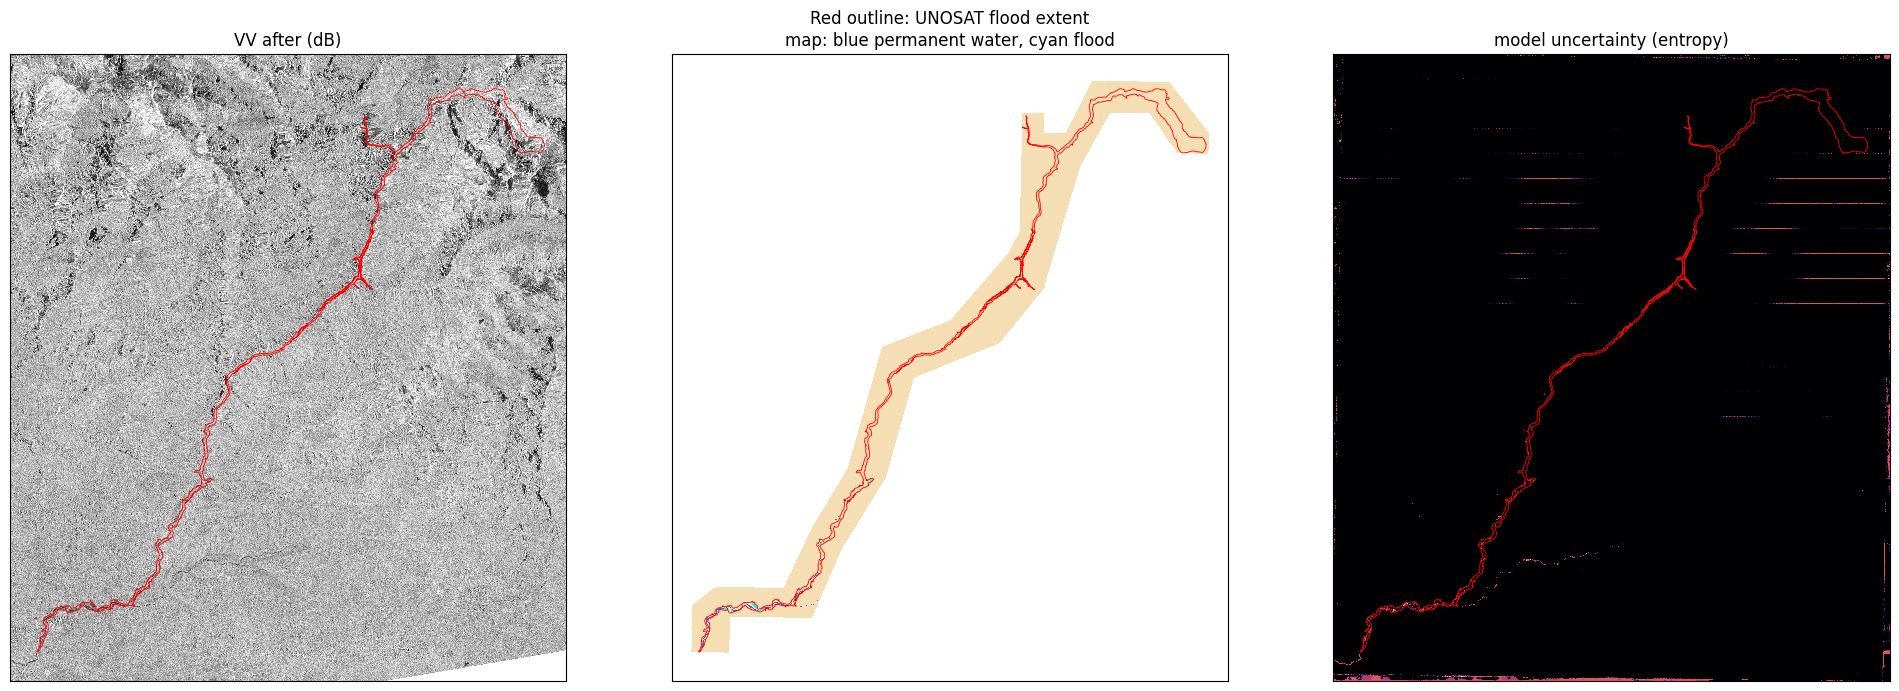

In [21]:
pred = prob.argmax(0)
entropy = -(prob * np.log(np.clip(prob, 1e-6, 1))).sum(0)
x0, x1 = scene["transform"].c, scene["transform"].c + scene["transform"].a * W
y1, y0 = scene["transform"].f, scene["transform"].f + scene["transform"].e * H
extent = (x0, x1, y0, y1)

def show(ax, img, title, **kw):
    ax.imshow(img, extent=extent, interpolation="nearest", **kw)
    scene["extent"].boundary.plot(ax=ax, color="red", linewidth=0.6)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])

water_map = np.where(pred == 2, 2, np.where(pred == 1, 1, 0)).astype(float)
water_map[~scene["in_area"]] = np.nan
panels = [(scene["s1"][1, 0], "VV after (dB)", dict(cmap="gray", vmin=-25, vmax=0)),
          (water_map, "map: blue permanent water, cyan flood", dict(cmap=ListedColormap(["wheat", "royalblue", "cyan"]), vmin=0, vmax=2)),
          (entropy, "model uncertainty (entropy)", dict(cmap="magma", vmin=0, vmax=1.1))]
fig, axes = plt.subplots(1, 3, figsize=(20, 7))
for ax, (img, title, kw) in zip(axes, panels):
    show(ax, img, title, **kw)
fig.suptitle("Red outline: UNOSAT flood extent")
plt.tight_layout()

The uncertainty (entropy) is near zero right where the flood was. So the model is confident there is no water along most of the corridor.

## Where should a person look?

Cells are ranked with the spotter trained on all 60 spotter events (cell tables from the spotter
notebook) and with the simpler rankings.

In [22]:
cells = nepal.scene_cells(prob, scene)
spot = pd.concat(pd.read_pickle(f) for f in sorted(glob.glob(f"{SPOTTER_DIR}/cells_spotter_fold*.pkl.gz")))
model = sp.fit_spotter(spot)
cells = sp.add_baseline_scores(cells)
cells["spotter"] = model.predict(cells[sp.FEATURES])
cells.to_pickle(f"{OUT_DIR}/cells.pkl.gz")

v = cells[cells.valid > 0]
print(f"{len(v)} cells in the analysis area, map wrong on {v.errors.sum() / v.valid.sum() * 100:.1f}% of its pixels")
nepal_capture = pd.Series({r: sp.capture(cells, r).captured.iloc[0] for r in RANKINGS})
nepal_capture.round(3)

3911 cells in the analysis area, map wrong on 9.7% of its pixels


,0
random,0.217
flood_fraction,0.200
entropy,0.332
spotter,0.378
oracle,1.000


Reviewing 20% of the area catches 33% of the errors with entropy and 38% with the spotter, against 22% at random. On the training-like floods it was about 80%.

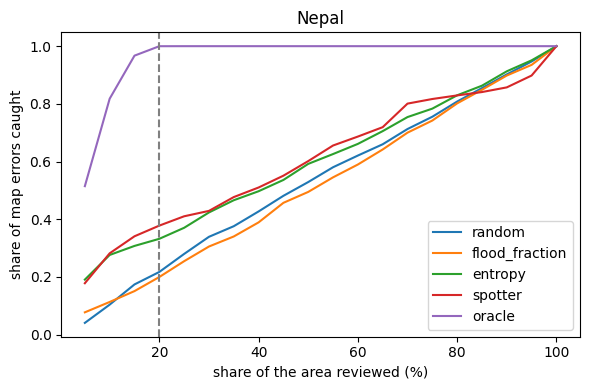

In [23]:
budgets = np.linspace(0.05, 1, 20)
fig, ax = plt.subplots(figsize=(6, 4))
for r in RANKINGS:
    ax.plot(budgets * 100, [sp.capture(cells, r, budget=b).captured.iloc[0] for b in budgets], label=r)
ax.axvline(20, ls="--", c="gray")
ax.set_xlabel("share of the area reviewed (%)"); ax.set_ylabel("share of map errors caught")
ax.set_title("Nepal"); ax.legend()
plt.tight_layout()

Entropy and the spotter stay only a little above random at every review size.

## Does the model know this map is unreliable? (exploratory)

Mean uncertainty of the map against its quality, one point per event: the 60 spotter events and the
12 holdout events (flood IoU) and Nepal (water IoU against UNOSAT, so not exactly the same measure).
This comparison was not part of the fixed set-up.

Nepal: mean entropy 0.003, water IoU 0.058
other events: mean entropy median 0.005, Nepal is higher than 31% of them


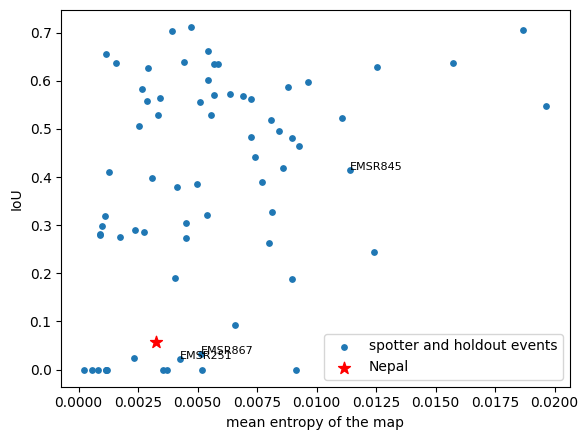

In [24]:
hold = pd.concat(pd.read_pickle(f) for f in sorted(glob.glob(f"{SPOTTER_DIR}/cells_holdout_*.pkl.gz")))
def mean_entropy(df):
    df = df[df.valid > 0]
    return (df.entropy_mean * df.valid).groupby(df.event).sum() / df.valid.groupby(df.event).sum()

iou = pd.read_csv(f"{RUN_DIR}/predictions/flood_iou_per_event.csv").set_index("event").iou
events = pd.DataFrame({"mean_entropy": mean_entropy(pd.concat([spot, hold])), "iou": iou}).dropna()
nepal_point = (mean_entropy(cells).iloc[0], scores.loc["water (flood or permanent)", "IoU"])

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(events.mean_entropy, events.iou, s=15, label="spotter and holdout events")
ax.scatter(*nepal_point, s=80, c="red", marker="*", label="Nepal")
for ev in ["EMSR867", "EMSR845", "EMSR251"]:
    if ev in events.index:
        ax.annotate(ev, (events.mean_entropy[ev], events.iou[ev]), fontsize=8)
ax.set_xlabel("mean entropy of the map"); ax.set_ylabel("IoU"); ax.legend()
plt.tight_layout()
print(f"Nepal: mean entropy {nepal_point[0]:.3f}, water IoU {nepal_point[1]:.3f}")
print(f"other events: mean entropy median {events.mean_entropy.median():.3f}, "
      f"Nepal is higher than {(events.mean_entropy < nepal_point[0]).mean() * 100:.0f}% of them")

The model is confidently wrong: Nepal's average uncertainty is lower than 69% of the other events. Across all events, average uncertainty does not track map quality, so it cannot warn that a whole map is unreliable.

## Answer

On a disaster unlike its training data, the model misses most of the flood and does not know it. Uncertainty-based review helps only a little here, so a reliability gate also needs a check on whether the input looks like the training data (here: steep mountain terrain).